In [1]:
##LSTM Model##

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
import os
os.chdir("/content/drive/My Drive/Deep_Learning_Project")
!ls

 analysis.py		   GRU_loss.png				    new_envirocar_tracks_csv
 constants.py		   imputed_envirocar_data		    old_data_Code.py
 data			  'Imputing Missing values in CSVs.ipynb'   __pycache__
 data_analysis.ipynb	  'LSTM Model.ipynb'			    README.md
 DataVisualization.ipynb   main_lstm.py				    track_df.csv
 envirocar_tracks_csv	   main.py				    Untitled.ipynb
 environment.yml	   models				    utils


In [3]:
# feature_list = [
#     'GPS Bearing(deg)',
#     'GPS Altitude(m)',
#     'O2 Lambda Current ER(ratio)',
#     'MAF(l/s)','Speed(km/h)',
#     'GPS Speed(km/h)',
#     'Rpm(u/min)',
#     'O2 Lambda Current(A)',
#     'Throttle Position(%)',
#     'Intake Pressure(kPa)',
#     'GPS Accuracy(%)',
#     'Intake Temperature(c)',
#     'Engine Load(%)',
#     'longitude',
#     'latitude'
# ]
target_value = 'CO2(kg/h)'
feature_list = [
    'GPS Bearing(deg)',
    'GPS HDOP(precision)',
    'GPS Altitude(m)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'engineDisplacement',
    'fuelType'
]

required_columns = [
    'id',
    'CO2(kg/h)',
    'GPS Bearing(deg)',
    'GPS HDOP(precision)',
    'GPS Altitude(m)',
    'Consumption(l/h)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'time'
]
download_output_dir = 'envirocar_tracks_csv'
original_delimiter = ';'

output_dir = 'imputed_envirocar_data'
delimiter_value = ','

# output_dir = 'envirocar_tracks_csv'
# delimiter_value = ';'

loss_image_dir = "loss_images"

all_columns_present_id_list = ['661245119828af15e2717fed', '6612450a9828af15e2717c76', '660b61e09828af15e232d0c3', '660b61da9828af15e232ce12', '65eeef0527de036499a72864', '65eeef0a27de036499a72b1b', '65ab9613769a4a5c859dbad6', '65ab9617769a4a5c859dbead', '65ab9626769a4a5c859dc49a', '65ab962a769a4a5c859dc820', '659fa485e4334e110cc91523', '65868308e4334e110cc30bc0', '6586830ce4334e110cc31030', '65868321e4334e110cc31e25', '65868325e4334e110cc32271', '657d6e21e4334e110c29a519', '657d6e27e4334e110c29a61d', '65716543e4334e110c24925a', '655efd4de4334e110cefdb1c', '655efd53e4334e110cefddca', '6520ed349186d0330638b754', '6520ed2f9186d0330638b4ac', '64fc075ade656f7b9eefe24f', '64fc075ade656f7b9eefe364',
                               '64fc0aebde656f7b9ef01ce2', '64b1008ac7e42807e7eabb2f', '64b10090c7e42807e7eabeb2', '649e5fc6c7e42807e751c2ff', '649e5fcac7e42807e751c64f', '64952e3cc7e42807e74b6939', '64952e41c7e42807e74b71d5', '648acd0ac7e42807e7038f32', '6482e20eca0a730aef0f3c67', '6481cd86ca0a730aefddb8f3', '64725ad0ca0a730aef50ed59', '646dc14dca0a730aef443b5f', '646dc174ca0a730aef445de9', '645f34ccca0a730aef36fad2', '645f34cfca0a730aef36fdb6', '644eb8cfca0a730aef197857', '644eb8d1ca0a730aef197b89', '642e5ebcca0a730aeffd3e7a', '642e5ebfca0a730aeffd4239', '642e5ec5ca0a730aeffd4672', '642e5ec8ca0a730aeffd46e3', '642e5ed7ca0a730aeffd53f5', '642e5edaca0a730aeffd54f6', '6412b1f05244bc763ca7d46d',
                               '6412b1f45244bc763ca7d868', '6412b2105244bc763ca7f447', '6412b2145244bc763ca7fb00', '6412b2195244bc763ca7ffdc', '64051f7d5244bc763c94a2fc', '64051f875244bc763c94af3f', '64051fca5244bc763c94e69f', '64077ad15244bc763c98acd2', '64077afa5244bc763c98cdd9', '64077b235244bc763c98d0f6', '64077b265244bc763c98d341', '64077b3f5244bc763c98e4ac', '64077b425244bc763c98e652', '64077b8d5244bc763c98f6a4', '64077b915244bc763c98fca6', '64077b9c5244bc763c990c5a', '64077ba35244bc763c99114a', '64077ba75244bc763c991740', '64077f055244bc763c99491e', '64077f085244bc763c994bb1', '64077f0c5244bc763c99511a', '640782125244bc763c99ade9', '651519169186d03306fb5057', '63a40768ad53a0015a4fe31d',
                               '63a4076bad53a0015a4fe663', '63949b6ead53a0015a096c91', '63948c5cad53a0015a08e2d8', '63948c57ad53a0015a08df35', '63948c1dad53a0015a08b5a1', '63948c1aad53a0015a08b34b', '63948c0aad53a0015a08a51c', '63948c03ad53a0015a08a1e2', '63948bffad53a0015a089f29', '63948b7cad53a0015a084327', '63948b78ad53a0015a084092', '63948aa3ad53a0015a079ee0', '63948925ad53a0015a071369', '63948921ad53a0015a070f6f', '6394891aad53a0015a070a21', '63948917ad53a0015a0706d5', '6394889ead53a0015a06afda', '6394889aad53a0015a06a962', '6394888fad53a0015a0692be', '62ad78db842171051aef8304', '629d9b11842171051acb48e8', '62932392842171051abbeead', '651519f69186d03306fb65d6', '6293239f842171051abbf23e',
                               '629323a7842171051abbf458', '62907ee5842171051ab80ab9', '62907ebf842171051ab7ff00', '62907eef842171051ab821ce', '628542a5842171051acbe8a8', '628542b6842171051acc0024', '628542a4842171051acbe33d', '628542a3842171051acbdf43', '6286a087842171051ace9dd9', '6286a093842171051ace9ff6', '607a2e173b14785a90ce8429', '607a2e1b3b14785a90ce885f', '5eec7aa7d6e3cf256ba3eff9', '5eb7582165b80c5d6be69f22', '5eb7582165b80c5d6be6a142', '5e8b930a65b80c5d6b4d7f2b', '5e42ccb63965f3689459b871', '5e24ca2463c90936dc7b2d94', '5e5e5ecd77e02d42aa94ee1c', '5e1eceab1126d80318bf9f7f', '5e10ec059115b85a123190d0', '5e10ec089115b85a12319686', '5e10ec059115b85a12318e62', '5e08bc845bc8db428964203d',
                               '5e08bc7b5bc8db428964101b', '5e08bc7a5bc8db4289640c77', '5e08bc795bc8db4289640945', '5e08bc795bc8db42896409d5', '5e08bc775bc8db42896406d8', '5e08bc785bc8db4289640875', '5e08bc775bc8db428964066d', '5e6256b977e02d42aa99f3fc', '5de9d7a03bdb691868e76540', '5de0cebf44ea85025c044a15', '5de0cebf44ea85025c044aed', '5ddfd2ba44ea85025c02d828', '5ddfd2bc44ea85025c02dbce', '5de9d7a63bdb691868e77e35', '5de9d7a03bdb691868e765cd', '5ddcdd4a44ea85025cfdf878', '5ddbc67f44ea85025cfc4c10', '5dda4b8144ea856b70e667f0', '5dd7afa244ea856b70e29ecc', '5dd7afa244ea856b70e29e44', '5dd7a23e44ea856b70e28a22', '5dd68af544ea856b70e1471a', '5dd68af244ea856b70e14259', '5dd68aef44ea856b70e140fc',
                               '5dd68aed44ea856b70e13eb5', '5dd68ae944ea856b70e1382b', '5dd68ae544ea856b70e1356b', '5dc985eb44ea856b702dd8c0', '5dc9864c44ea856b702e048a', '5dc986e844ea856b702e3cb5', '5dc9879b44ea856b702e872d', '5dc9c2fe44ea856b7034cbb4', '5dca980744ea856b70363f64', '5dca9b6b44ea856b70364378', '5dcab52c44ea856b70365911', '5dcab5f044ea856b70365f6a', '5dcad90f44ea856b703681ea', '5dcad8d944ea856b70367f91', '5dcad83844ea856b70367d81', '5dcead5644ea856b704d8882', '5dcead4644ea856b704d8428', '5dcbbb1444ea856b7037b264', '5dcead4044ea856b704d8037', '5dcbbb0d44ea856b7037ae6e', '5dcbbb0244ea856b7037ab04', '5dcbb93044ea856b7037a58a', '5dca8b0244ea856b7036389b', '5dca7dce44ea856b70362ef8',
                               '5dcad99b44ea856b70368833', '5dcad96444ea856b70368445', '5dca7e7c44ea856b70363072', '5d757dff44ea853f9f7f62aa', '5d757df644ea853f9f7f6174', '5d746ed344ea853f9f7e5075', '5d5c42ab44ea8550236462ea', '5d59ad7044ea855023610e7e', '5d59ad5b44ea8550236107e0', '5d51f49844ea85502359591b', '5d51f49444ea855023595716', '5d51f48544ea855023594ea6', '5d336ae244ea855023d3745e', '5d336ade44ea855023d372d7', '5d222f4644ea855023c1d0c0', '5d222f2844ea855023c1c8f0', '5d222f2244ea855023c1c7f9', '5d15eef544ea855023b4456f', '5ced330544ea850302918bec', '5ced358044ea850302922200', '5ced359f44ea8503029222ae', '5c95155944ea850302f58228', '5c8c120944ea85030266906a', '5c8c1cc244ea850302669b50',
                               '5c718e9844ea85030245e824', '5c6dba6c44ea85030209b9ae', '5c6dc37c44ea85030209bbc1', '5c684aea44ea850302048409', '5c6844a544ea85030204806f', '5c60075444ea850302fbddf7', '5c5edd0c44ea850302fa9dcd', '5c5edd2744ea850302faa614', '5c28ccc244ea850302c4fd98', '5c28f94644ea850302c50153', '5c26511444ea850302c2d5bf', '5c263bbc44ea850302c2d2b9', '5c0971e344ea8503029b8a83', '5c096abd44ea8503029afd17', '5bfa55dd44ea8503028f0d2e', '5bf9162d44ea8503028df2cf', '5bf90edc44ea8503028df1b2', '5bf8376a44ea8503028ce7af', '5bf831d144ea8503028ce6ee', '5ba9ecf344ea8508426dd940', '5b8847bf44ea8508429306f9', '5b88441b44ea850842930670', '5b76e4f844ea8508423c57d2', '5b74809e44ea8508423177f4',
                               '5b6dd5c644ea85084220335f', '5b6dd3a144ea8508421ffe91', '5b27e0d644ea85091053c8cb', '5b27a84844ea85091053b86f', '5b1cfe7544ea8508ccf04471', '5b1cf8fa44ea8508ccf03cfc', '5ad2479644ea8508c543f14b', '5ad2114844ea8508c543bce1', '5acf80fb44ea8508c53e3cb4', '5a981a8944ea851012d70797', '5a98156544ea851012d68d18', '5a89ceae44ea851012bcc8f5', '5a89cbba44ea851012bcbee4', '5a7f8ea244ea851012b1cae2', '5a7f843d44ea851012b1ca88', '5a7f82d244ea851012b1c4ae', '5a7f564f44ea851012b1b9e7', '5a7f4d4a44ea851012b1b247', '5a625b5a44ea8508ffa54197', '5a61c09544ea85087e7a8d86', '5a61c09344ea85087e7a8bf3', '5a61ae2044ea85087e7a82df', '5a60e7b044ea85087e7a7344', '5a5a5bc944ea85087e6bf7b3',
                               '5a34130f44ea8513da639e87', '5a3412fb44ea8513da639d87', '5a2c14ed268d1b08cd0c27ec', '5a2c14ea268d1b08cd0c1e79', '59cd1eb9268d1b086009a72e', '593165ec268d1b08a4ac122b', '59316592268d1b08a4abfaaa', '59316529268d1b08a4abe33c', '59316569268d1b08a4abee8e', '59249f41268d1b08a49e0507', '59249f30268d1b08a49dfae5', '5915c1f0268d1b08a48d36b2', '5915c1b3268d1b08a48d2a28', '5914078d268d1b08a48bc5fb', '59033b83268d1b08a46be37a', '59033b7b268d1b08a46bd92c', '585198a2e4b0a979d5571317', '5851871de4b0a979d5571212', '57813841e4b0ea2464510f5e', '5760009ee4b091b7fc69d5ca', '5760009ce4b091b7fc69d377', '575bca4ae4b0a69192a28d73', '575bca49e4b0a69192a28be9', '575b17d3e4b0a69192a213b2',
                               '575a63bbe4b0a691929d1f30', '575a63b5e4b0a691929d1c92', '57593b13e4b0a6919296818f', '575860c3e4b0a6919294351a', '575826c1e4b0a6919292205e', '575826bfe4b0a69192921ec8', '5755a4a7e4b0a691928224f9', '57553109e4b0a691927df43a', '573aba1ce4b09078f96804c0', '57337c7fe4b09078f961f02b', '5705764ee4b0b5e237edae2a', '5705764be4b0b5e237edac7f', '57057648e4b0b5e237edab37', '56f120ede4b0b5e237d5756f', '56ee65abe4b0b5e237d32e7f', '56c4766fe4b0df8fa0524f2f', '56c22080e4b0df8fa05006da', '56bbae8ce4b0df8fa021e387', '56bbae8ae4b0df8fa021e284', '56b4dd7de4b0df8fa00669aa', '56b464a2e4b0df8fa005c794', '56b326c0e4b0df8fa0058105', '56b318e8e4b0df8fa0057d11', '56b3170de4b0df8fa0057314',
                               '56b21cede4b0df8fa004baee', '56b21ceae4b0df8fa004b85c', '56af2fb6e4b058e54940a0c2', '56af2fb3e4b058e54940a022', '56a87695e4b000f94dbbc0d5', '56a781bbe4b000f94dbb91d0', '569635d6e4b000f94da7ff63', '569635d1e4b000f94da7fc7c', '567aa2cfe4b000f94d91c837', '567aa2a8e4b000f94d91c72d', '554ce07de4b048885ee0dfa7', '552bff35e4b0bf5f3e46d683', '552bff31e4b0bf5f3e46d3fc', '552418ace4b0bf5f3e43d3ad', '55241876e4b0bf5f3e43a4aa', '553aa4b9e4b080c763779442', '553aa525e4b080c76377a19d', '553aa4b2e4b080c76377917f', '553aa4e9e4b080c763779eda', '55080c87e4b0bf5f3d061b07', '55080c7ee4b0bf5f3d061868', '55241838e4b0bf5f3e437753', '54fda58ae4b0bf5f3cf0d400', '54fda589e4b0bf5f3cf0d0f9',
                               '54fc4853e4b0bf5f3ceb0ad3', '54fc484de4b0bf5f3ceb097c', '54fda585e4b0bf5f3cf0ce0a', '54e30adbe4b0558690c54e8e', '54ec23d6e4b0558690c83df7', '54ec2575e4b0558690c894b3', '54ec2ad2e4b0558690c8e968', '54ec2f1ee4b0558690c939fa', '54ec3350e4b0558690c9809a', '54ec23d1e4b0558690c83b00', '54ec256fe4b0558690c891bc', '54ec2acce4b0558690c8e671', '54ec2f18e4b0558690c93703', '54e30acce4b0558690c54ba8', '54e30a82e4b0558690c54556', '54706aa8e4b094c1030086ea', '53b514bee4b01607fa560ce2', '53b3b0dee4b01607fa556250', '53b3b0f8e4b01607fa5591f5', '53b3b0d6e4b01607fa554637', '53b3b0f0e4b01607fa558784', '53b3b0cde4b01607fa552940', '53b3b0e8e4b01607fa5575d5', '53b3b066e4b01607fa54ed80',
                               '53b2cda1e4b01607fa5454e1', '53b2cd91e4b01607fa544f12', '53b2cd7de4b01607fa544927', '53b2cd6ae4b01607fa54417c', '53b27494e4b01607fa538d1d', '53b5228ee4b01607fa566b78', '53b52282e4b01607fa566469', '53b27449e4b01607fa53736d', '53b52277e4b01607fa565fa6', '53b52266e4b01607fa5656d3', '5371e972e4b05e62155002c4', '5371e96ce4b05e62154ff5ad', '535e0898e4b0976b09bda467', '535e0896e4b0976b09bda210', '5357a002e4b0976b09b935d0', '53579ffce4b0976b09b91b09', '53218b43e4b0c917fe59aa8f', '52f6c62de4b0d8e8c28df6a2', '52eabd02e4b0d8e8c250ca6d', '52e39b02e4b0d8e8c22665c3', '52caf543e4b0f9afbd8d7f8c', '52b19f7ce4b0f9afbd14d773', '52b19f7ae4b0f9afbd14d3a0', '52af4fe9e4b0593cce13cf5d',
                               '52af4fe4e4b0593cce13ccc6', '52af4fe1e4b0593cce13cc37', '528f1a19e4b0ca505ba93418', '528f1a23e4b0ca505ba943d3', '528f1a16e4b0ca505ba92f41', '528f1a20e4b0ca505ba93efc', '52af4fd3e4b0593cce13bfc7', '52af4fd0e4b0593cce13bebc', '528bd8b1e4b08cecc5a6f8bc', '528349ade4b08cecc5a0a0b8', '528349bee4b08cecc5a0b98d']

In [4]:
import matplotlib.pyplot as plt


def plot_loss(train_losses, val_losses, model_name ="LSTM"):
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Training loss')
    plt.plot(val_losses, label='Validation loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.savefig(loss_image_dir +"/" +model_name + "_loss.png")
    #plt.show()

In [5]:
##LSTM model##
import torch
import torch.nn as nn
import torch.optim as optim


class LSTM(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, device):
        super(LSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1)
        self.device = device

    def forward(self, x): #x should be [batch_size, sequence length, input size]
        x = x.to(self.device)
        out, _ = self.lstm(x)

        #Passing the output through the linear layer to transform it to desired output size
        out = self.linear(out[:, -1, :])
        out = out.to(self.device)
        return out #output tensor=model's predictions

class LSTMModel():
    def __init__(self, input_size, hidden_size=64, num_layers=2, lr=0.001, batch_size=64):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        # Check for Metal Performance Shaders availability on macOS (for M1/M2 chips)
        self.device = torch.device('mps' if torch.backends.mps.is_available() else self.device)
        self.model = LSTM(input_size, hidden_size, num_layers, self.device).to(self.device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.criterion = nn.MSELoss() #Loss function=MSE Loss
        self.train_losses = []
        self.val_losses = []
        self.batch_size= batch_size
        self.name = "LSTM"

    def get_dataloader_obj(self, X,y, shuffle=True):
        X = X.to(self.device)
        y = y.to(self.device)
        dataset = torch.utils.data.TensorDataset(X, y)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle)
        return dataloader

    #training the LSTM using the training data
    def train(self, dataloader):
        self.model.train()
        ind = 0
        train_loss=0
        for inputs, labels in dataloader:
            self.optimizer.zero_grad()
            inputs, labels = inputs.to(self.device), labels.to(self.device)
            outputs = self.model(inputs)
            loss = self.criterion(outputs, labels)
            loss.backward()
            self.optimizer.step()
            ind+=1
            train_loss += loss.item()
        train_loss /= len(dataloader.dataset)
        self.train_losses.append(train_loss)


    def validate(self, dataloader, epochs=40):
        self.model.eval()
        val_loss = 0
        device= self.device
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, labels)
                val_loss += loss.item()
        val_loss /= len(dataloader.dataset)
        self.val_losses.append(val_loss)

    def plot_analysis(self):
        print("trainloss", self.train_losses)
        print("validationloss", self.val_losses)
        plot_loss(self.train_losses, self.val_losses, self.name)

    def run_model(self, train, test, epochs=40):
        (train_x, train_y) = train
        (test_x, test_y) = test

        train_dataloader = self.get_dataloader_obj(train_x, train_y, True)
        test_dataloader = self.get_dataloader_obj(test_x, test_y, True)

        for epoch in range(epochs):
            self.train(train_dataloader)
            self.validate(test_dataloader)

        self.plot_analysis()


In [30]:
##data init

import csv
from random import shuffle

import pandas as pd
import requests
import os
from io import StringIO

import torch

def set_trackdf():
    track_df = pd.read_csv('track_df.csv')
    global global_track_df_object
    global_track_df_object = track_df

def divide_track_ids():
    unique_ids = all_columns_present_id_list
    shuffle(unique_ids)
    total = len(unique_ids)
    print("total unique", total)
    train = int(0.8 * total)
    train_ids = unique_ids[:train]
    test_ids = unique_ids[train:]
    return train_ids, test_ids

def divide_sequences(X, Y):
    n = X.shape[0]
    indices = torch.randperm(n)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]
    split = int(0.75 * n)
    train_X = shuffled_X[:split]
    train_Y = shuffled_Y[:split]

    test_X = shuffled_X[split:]
    test_Y = shuffled_Y[split:]

    return (train_X, train_Y), (test_X, test_Y)

def create_sequences(data, target=target_value, features=feature_list, sequence_length=10):
    X, y = [], []
    total = len(data)
    #print("columns", data.columns)
    #print("features",features)
    for i in range(sequence_length, total):
        if (total-i >= sequence_length): # dropping end sequences
            X.append(data[features].iloc[i-sequence_length:i].values)
            y.append(data[target].iloc[i])
            #print("y", data[target].iloc[i])
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def simple_hash_for_fuel_type(fuelType):
    return hash(fuelType) % 10
def read_data(ids, normalised = False):
    track_df = global_track_df_object
    excluded_columns = ['id', 'time', 'track.begin', 'track.end']
    track_df = track_df.drop(columns=excluded_columns, errors='ignore')
    X = []
    y = []
    total_count = 0
    big_df = []
    for track_id in ids:
        csv_file = f'{output_dir}/{track_id}.csv'
        df = pd.read_csv(csv_file,delimiter=delimiter_value)
        df['time'] = pd.to_datetime(df['time'])
        tr = track_df[track_df['track.id'] == track_id]
        df['engineDisplacement'] =tr['sensor.engineDisplacement']
        df['fuelTypeString'] = tr['sensor.fuelType']
        df['fuelType'] = df['fuelTypeString'].apply(lambda x: simple_hash_for_fuel_type(x))
        # df[target_value].fillna(method='ffill', inplace=True)
        df['engineDisplacement'].fillna(method='ffill', inplace=True)
        # df.fillna(df.mean(numeric_only=True), inplace=True)
        # Handling other numerical columns by filling NaNs with mean or median
        # Handling NaNs comprehensively
        df.fillna(method='ffill', inplace=True)  # First, forward fill to maintain data consistency across time
        # Handling other numerical columns by filling NaNs with mean or median
        numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
        for col in numerical_cols:
            df[col] = df[col].fillna(df[col].mean())


        big_df.append(df)
        #print("df.decribe", df.describe())
        #break;
        #print("type", type(df))
        total_count += len(df)
        seq_x, seq_y = create_sequences(df)
        X.append(seq_x)
        y.append(seq_y)
        #
        # print("shape sw", seq.shape)
        # for label, content in df.items():
        #     print(f'label: {label}')
        #     print(f'content: {content}', sep='\n')
        # break;
    print("shapes", len(X), len(y), X[0].shape, y[0].shape)
    single_df = pd.concat(big_df)
    big_X = torch.cat(X)
    big_y = torch.cat(y).unsqueeze(1)

    if (not normalised):
        return big_X, big_y, single_df
    else:
        min_vals_X = big_X.min(dim=0, keepdim=True)[0].min(dim=1, keepdim=True)[0]
        max_vals_X = big_X.max(dim=0, keepdim=True)[0].max(dim=1, keepdim=True)[0]

        min_vals_y = big_y.min(dim=0, keepdim=True)[0]
        max_vals_y = big_y.max(dim=0, keepdim=True)[0]
        normalized_X = (big_X - min_vals_X) / (max_vals_X - min_vals_X)
        normalized_y = (big_y - min_vals_y) / (max_vals_y - min_vals_y)
        #print("single_df", single_df.describe())
        return normalized_X, normalized_y, single_df

def get_columns(df):
    columns = []
    datatype = []
    for column in df:
        columns.append(column)
        datatype.append(df[column].dtype)
    return columns, datatype

def check_columns(df, required_columns):
    return set(required_columns).issubset(df.columns)


In [31]:
import sys

In [32]:
if __name__ == '__main__':
    print("started")
    set_trackdf()
    it_name = ""
    if(len(sys.argv) > 1):
        it_name = sys.argv[1]
    print("it", it_name)
    X, Y, sdf = read_data(all_columns_present_id_list, True)
    print("singleDF", sdf.describe())
    (train_x, train_y), (test_x, test_y) = divide_sequences(X, Y)
    #download_data()
    # train_ids, test_ids = divide_track_ids()
    #
    # train_x, train_y,_ = read_data(train_ids)
    # test_x, test_y,_ = read_data(test_ids)
    print("shape train::", train_x.shape, train_y.shape)
    print("shape test::", test_x.shape, test_y.shape)
    #download_track_df()

started


<ipython-input-30-eede4673e8e2>:14: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  track_df = pd.read_csv('track_df.csv')


it -f
shapes 371 371 torch.Size([109, 10, 10]) torch.Size([109])
singleDF            CO2(kg/h)  GPS Bearing(deg)  GPS Altitude(m)  GPS HDOP(precision)  \
count  136901.000000     136901.000000    136901.000000        136901.000000   
mean        8.382746        194.398726       108.799910             1.063319   
std         7.263331        115.160108        15.166514             6.195573   
min         0.000000     -12531.713536        16.000000           -34.500000   
25%         3.814497        109.342300       102.113739             0.800000   
50%         5.572855        191.472280       107.240863             0.900000   
75%        11.198872        294.399994       113.900002             1.000000   
max       267.768457       3583.049809       259.000000           500.000000   

       Consumption(l/h)  Maximum Acceleration(m/s²)    Speed(km/h)  \
count     136901.000000                40915.000000  136901.000000   
mean           3.567126                   -0.006671      38.44811

In [41]:
lstm_model = LSTMModel(input_size=train_x.shape[2], hidden_size=64, num_layers=4, lr=0.001)


In [25]:
lstm_model.batch_size

64

In [35]:
train_x

tensor([[[0.7972, 0.0657, 0.3934,  ..., 0.7531,    nan, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531,    nan, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7533,    nan, 1.0000],
         ...,
         [0.7972, 0.0657, 0.3934,  ..., 0.7533,    nan, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531,    nan, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531,    nan, 1.0000]],

        [[0.7830, 0.0666, 0.3866,  ..., 0.7533,    nan, 1.0000],
         [0.7830, 0.0666, 0.3858,  ..., 0.7544,    nan, 1.0000],
         [0.7830, 0.0664, 0.3841,  ..., 0.7535,    nan, 1.0000],
         ...,
         [0.7831, 0.0664, 0.3801,  ..., 0.7537,    nan, 1.0000],
         [0.7830, 0.0664, 0.3787,  ..., 0.7535,    nan, 1.0000],
         [0.7831, 0.0666, 0.3782,  ..., 0.7542,    nan, 1.0000]],

        [[0.7863, 0.0659, 0.3580,  ..., 0.7527,    nan, 1.0000],
         [0.7862, 0.0659, 0.3663,  ..., 0.7526,    nan, 1.0000],
         [0.7862, 0.0659, 0.3704,  ..., 0.7528,    nan, 1.

In [36]:
if torch.isnan(train_x).any():
    # Compute the mean of non-NaN elements
    mean_val = torch.nanmean(train_x)
    # Replace NaNs with the computed mean value
    train_x = torch.where(torch.isnan(train_x), mean_val, train_x)

print(train_x)

tensor([[[0.7972, 0.0657, 0.3934,  ..., 0.7531, 0.4756, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531, 0.4756, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7533, 0.4756, 1.0000],
         ...,
         [0.7972, 0.0657, 0.3934,  ..., 0.7533, 0.4756, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531, 0.4756, 1.0000],
         [0.7972, 0.0657, 0.3934,  ..., 0.7531, 0.4756, 1.0000]],

        [[0.7830, 0.0666, 0.3866,  ..., 0.7533, 0.4756, 1.0000],
         [0.7830, 0.0666, 0.3858,  ..., 0.7544, 0.4756, 1.0000],
         [0.7830, 0.0664, 0.3841,  ..., 0.7535, 0.4756, 1.0000],
         ...,
         [0.7831, 0.0664, 0.3801,  ..., 0.7537, 0.4756, 1.0000],
         [0.7830, 0.0664, 0.3787,  ..., 0.7535, 0.4756, 1.0000],
         [0.7831, 0.0666, 0.3782,  ..., 0.7542, 0.4756, 1.0000]],

        [[0.7863, 0.0659, 0.3580,  ..., 0.7527, 0.4756, 1.0000],
         [0.7862, 0.0659, 0.3663,  ..., 0.7526, 0.4756, 1.0000],
         [0.7862, 0.0659, 0.3704,  ..., 0.7528, 0.4756, 1.

In [37]:
if torch.isnan(test_x).any():
    # Compute the mean of non-NaN elements
    mean_val = torch.nanmean(test_x)
    # Replace NaNs with the computed mean value
    test_x = torch.where(torch.isnan(test_x), mean_val, test_x)

print(test_x)

tensor([[[0.7886, 0.0662, 0.3374,  ..., 0.7532, 0.4755, 1.0000],
         [0.7886, 0.0662, 0.3457,  ..., 0.7529, 0.4755, 1.0000],
         [0.7887, 0.0662, 0.3663,  ..., 0.7532, 0.4755, 1.0000],
         ...,
         [0.7897, 0.0662, 0.3704,  ..., 0.7529, 0.4755, 1.0000],
         [0.7903, 0.0662, 0.3457,  ..., 0.7527, 0.4755, 1.0000],
         [0.7900, 0.0662, 0.3374,  ..., 0.7526, 0.4755, 1.0000]],

        [[0.7979, 0.0660, 0.3449,  ..., 0.7535, 0.4755, 1.0000],
         [0.7979, 0.0660, 0.3453,  ..., 0.7535, 0.4755, 1.0000],
         [0.7979, 0.0660, 0.3457,  ..., 0.7539, 0.4755, 1.0000],
         ...,
         [0.7979, 0.0660, 0.3541,  ..., 0.7539, 0.4755, 1.0000],
         [0.7979, 0.0660, 0.3563,  ..., 0.7539, 0.4755, 1.0000],
         [0.7978, 0.0660, 0.3580,  ..., 0.7539, 0.4755, 1.0000]],

        [[0.7864, 0.0664, 0.3994,  ..., 0.7531, 0.4755, 1.0000],
         [0.7864, 0.0664, 0.3997,  ..., 0.7531, 0.4755, 1.0000],
         [0.7864, 0.0664, 0.4001,  ..., 0.7530, 0.4755, 1.

trainloss [6.495898286748657e-05, 5.2563946190583666e-05, 4.9703194563949724e-05, 4.816956928931129e-05, 4.609325776710285e-05, 4.496771898336272e-05, 4.334204508971045e-05, 4.202634306229895e-05, 4.0789425292490907e-05, 4.0160164968325054e-05, 3.947256187537285e-05, 3.90989908504036e-05, 3.870410787584618e-05, 3.827854035467818e-05, 3.764850787700911e-05, 3.7265565199296975e-05, 3.686767281725172e-05, 3.6426571475378155e-05, 3.594047458665685e-05, 3.575363913642771e-05, 3.5188843560354824e-05, 3.4896285728349156e-05, 3.4332813805063766e-05, 3.3949754134704475e-05, 3.367055748563088e-05, 3.32231268676035e-05, 3.294557928677545e-05, 3.239209427380856e-05, 3.191121950276264e-05, 3.156141611652824e-05, 3.1201247883749946e-05, 3.093263880628007e-05, 3.0463889392637974e-05, 3.0072119457855567e-05, 2.976964256470461e-05, 2.9184118269108053e-05, 2.8997603497998215e-05, 2.8469130291227085e-05, 2.822263478793208e-05, 2.7804683903098822e-05]
validationloss [5.498796511164927e-05, 5.4132770867431

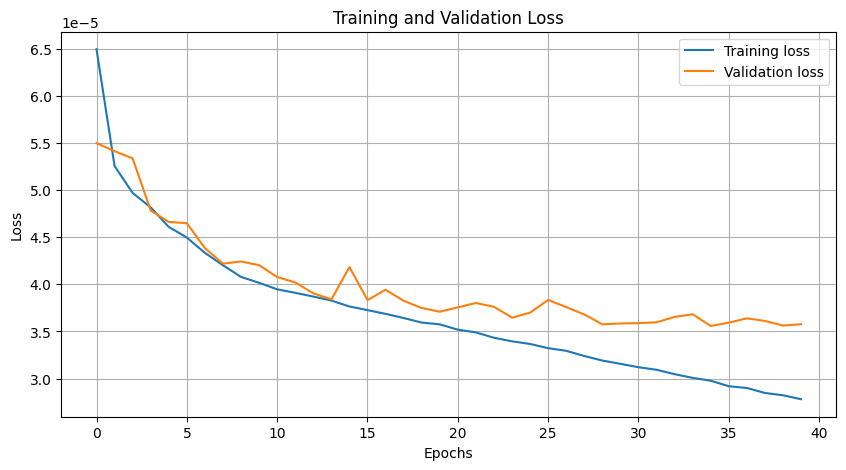

In [42]:
lstm_model.run_model((train_x,train_y), (test_x, test_y))